In [1]:
import json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from astropy.io import fits
from astropy.io import fits
from astropy.table import Table
import json
import sys

C:\Users\javas\anaconda3\envs\viento\Lib\site-packages\seaborn\_statistics.py:32: UserWarning: A NumPy version >=1.23.5 and <2.3.0 is required for this version of SciPy (detected version 2.3.0)
  from scipy.stats import gaussian_kde


In [2]:
sys.path.append(str(Path().resolve() / 'py_modules')) 

import list_maps_plots
from spectral_lines import LINES, print_available_lines

#  Data

In [3]:
cfg = LINES["Halpha"]

plot_label_line      = cfg.plot_label
rest_wavelength = cfg.rest_wavelength
wavelength_id    = cfg.wavelength_id
element         = cfg.element
ion             = cfg.ion
transition_id   = cfg.transition_id

In [4]:
print(plot_label_line)
print(rest_wavelength)
print(wavelength_id)
print(element)
print(ion)
print(transition_id)

H$\alpha$
6562.8
6563
H
H_I
H_I-6563


In [5]:
#line        = r'H$\alpha$'
#lambda_rest = 6562.8
#line_id     = 'H'
#line_id2   = "6563"

In [6]:
# Data from observations
bins        = 0

region     = 'NGC 2070'
name_reg   = '30 Doradus'
reg_id     = '30Dor'
inst       = 'FLAMES'
inst_id    = 'FLAMES'
type_obj   = 'H II region'

pix        = 0   # Instrument resolution [arcsec/pix]
dist       = 50000 # Distance [parsecs]
s0_        = 0.9    # proposed seeing

pc         = dist*(2*np.pi) / (360 * 60 * 60)
s0         = (s0_*pc)

#Since we are working with scatter adata there is no binning that can be applied
name_file    =  inst_id + '-' + reg_id + '-' + str(wavelength_id)
name_id      =  inst_id + '-' + reg_id + '-' + element + "-X"
print(name_file)
print(name_id)


FLAMES-30Dor-6563
FLAMES-30Dor-H-X


In [7]:
_data = json.load(open('observations/'+ name_file + '-l.json'))
_line = pd.DataFrame(_data['data'])
_line.columns = ['RAdeg', 'DEdeg', 'V_mean','log_F','sigma']
#_line = _line[0:3500]

In [8]:
_line.head()

,RAdeg,DEdeg,V_mean,log_F,sigma
0,84.550875,-69.148917,-2.775576,3.980130,10.705632
1,84.634750,-69.088028,4.344645,5.050337,11.376043
2,84.852375,-69.082583,-33.764827,4.063845,10.314624
3,84.610125,-69.163389,-0.596002,3.892574,15.575936
4,84.460167,-69.170167,1.242338,4.282470,5.439301


In [9]:
from astropy.coordinates import SkyCoord
import astropy.units as u
from astropy.wcs import WCS

c0 = SkyCoord.from_name("Tarantula")
c0

<SkyCoord (ICRS): (ra, dec) in deg
    (84.675, -69.1)>

In [10]:
fov_deg = 1.0  # Total field of view in degrees (width and height)
pix_scale = 1 / 3600
npix = int(fov_deg / pix_scale)

# Create WCS for TAN projection centered at 'center'
wcs = WCS(naxis=2)
wcs.wcs.ctype = ["RA---TAN", "DEC--TAN"]
wcs.wcs.crval = [c0.ra.deg, c0.dec.deg]
wcs.wcs.crpix = [npix, npix]  # center of your "image"
wcs.wcs.cdelt = [-pix_scale, pix_scale]  # field size / pixel count

In [11]:
ra0  = c0.ra.deg
dec0 = c0.dec.deg
#ra0 = _line["RAdeg"].median()
#dec0 = _line["DEdeg"].median()
print(ra0, dec0)

84.675 -69.1


In [12]:

centro = SkyCoord(ra=ra0*u.deg, dec=dec0*u.deg, frame='icrs')

coords = SkyCoord(
    ra=_line["RAdeg"].values * u.deg,
    dec=_line["DEdeg"].values * u.deg,
    frame='icrs'
)

radio = 3305 * u.arcsec   
sep = coords.separation(centro)

line_rad = _line[sep <= radio]


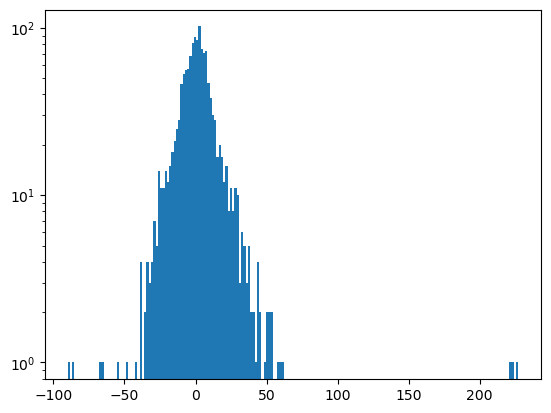

In [13]:
fig, ax = plt.subplots()
plt.hist(line_rad["V_mean"] , bins=200)
ax.set_yscale("log")

In [14]:
mask = (line_rad["V_mean"] > -45) & (line_rad["V_mean"]<+45) 
line_mask = line_rad[mask]

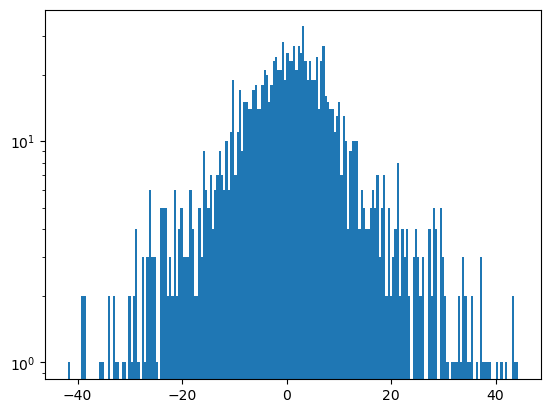

In [15]:
fig, ax = plt.subplots()
plt.hist(line_rad["V_mean"][mask] , bins=200)
ax.set_yscale("log")

Plot flux and radial velocity

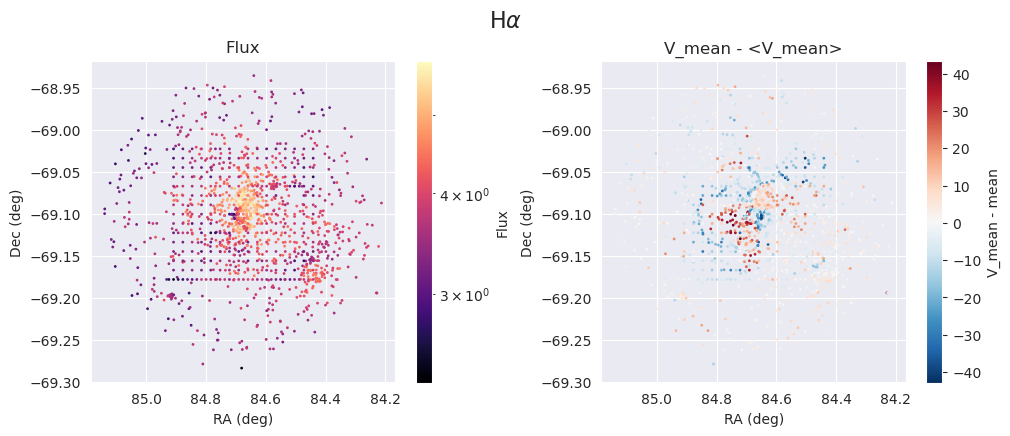

In [16]:
fig, ax = list_maps_plots.plot_panels_log_title(line_mask,
                                                s=1.0,
                                                figsize=(10, 4.25),
                                                titles=("Flux", "V_mean - <V_mean>"),
                                                figure_title=plot_label_line)
plt.show()
#plt.savefig('Imgs/' + name_file + '.jpg', bbox_inches='tight')

Text(0, 0.5, 'Dec (deg)')

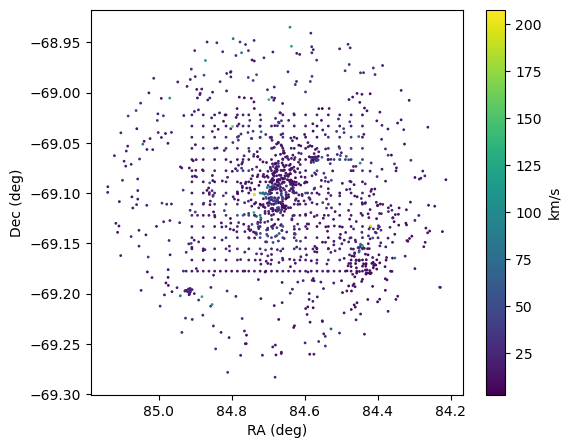

In [17]:
fig, ax = plt.subplots(figsize = (6,5))
sig_map = ax.scatter(line_mask['RAdeg'],
            line_mask['DEdeg'], 
            c=line_mask['sigma'],
            s = 1.0)

fig.colorbar(sig_map, ax=ax, label='km/s')
ax.invert_xaxis()
ax.set_xlabel("RA (deg)")
ax.set_ylabel("Dec (deg)")

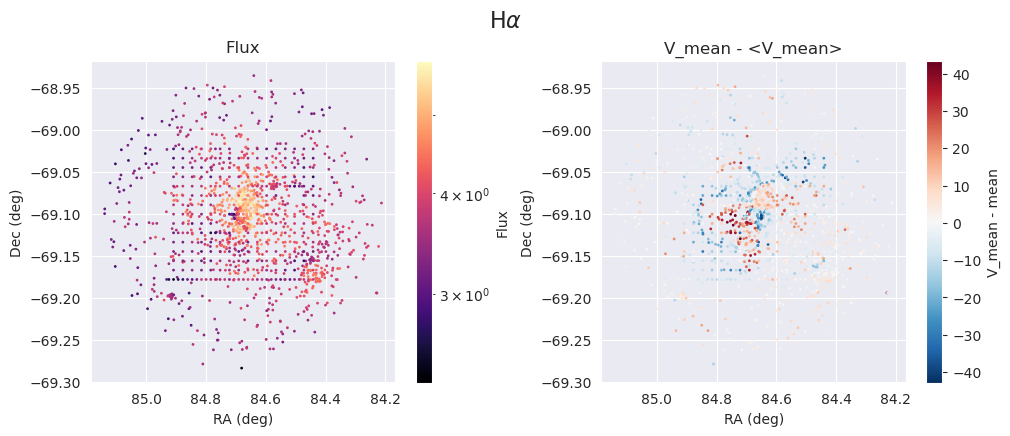

In [18]:
fig, ax = list_maps_plots.plot_panels_log_title(line_mask,
                                                s=1.0,
                                                figsize=(10, 4.25),
                                                titles=("Flux", "V_mean - <V_mean>"),
                                                figure_title=plot_label_line)
plt.show()
#plt.savefig('Imgs/' + name_file + '.jpg', bbox_inches='tight')

Plot flux and radial velocity in WCS

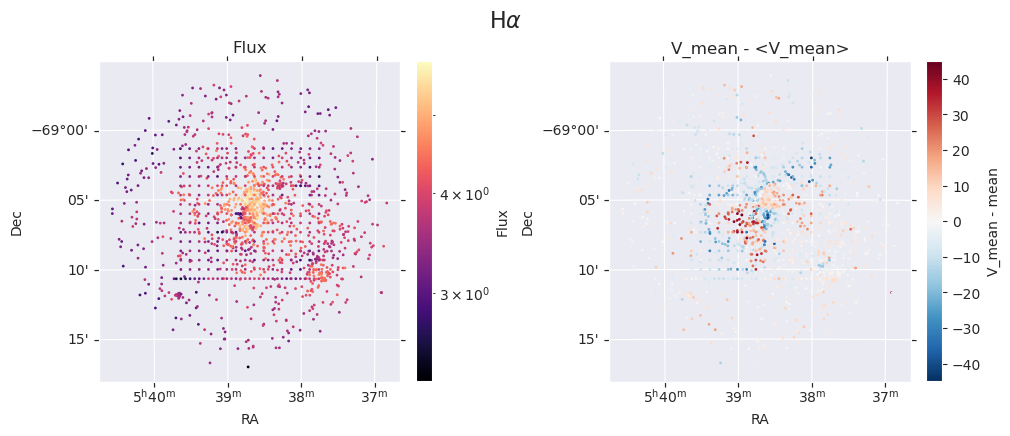

In [19]:
fig, ax = list_maps_plots.plot_panels_wcs(line_mask,
                                          wcs,
                                          s=1.0,
                                          figsize=(10, 4.25),
                                          invert_ra=False, 
                                          titles=("Flux", "V_mean - <V_mean>"),
                                          figure_title=plot_label_line)
plt.show()

#plt.savefig('Imgs/' + name_file + '.jpg', bbox_inches='tight')

In [20]:
_line = line_mask.copy()

In [21]:
#N = np.sqrt((_line.RAdeg.max()-_line.RAdeg.min())*(_line.DEdeg.max()-_line.DEdeg.min())) * pc * 3600
sig       = _line['V_mean'].std()

In [24]:
# Angular extents in degrees
delta_ra = _line.RAdeg.max() - _line.RAdeg.min()
delta_dec = _line.DEdeg.max() - _line.DEdeg.min()

# Representative declination
dec0 = _line.DEdeg.median()

# Projection correction
delta_ra_proj = delta_ra * np.cos(np.deg2rad(dec0))

# Physical dimensions in pc
Lx = delta_ra_proj * 3600 * pc
Ly = delta_dec * 3600 * pc

# Characteristic box size in pc
L = np.sqrt(Lx * Ly)

# Bounding-box area in pc²
A_box = Lx * Ly

In [28]:
N = L
print(N)

296.05397171359084


# Export 

In [29]:
t         = Table.from_pandas(_line.reset_index(drop=True))
table_hdu = fits.BinTableHDU(t, name=name_file)

# primary HDU
primary = fits.PrimaryHDU()
hdr = primary.header

hdr["FILE"]       = (name_file, "Fits file name")
hdr["NAME_ID"]    = (name_id, "pipeline identifier")
hdr["REG"]       = (region, "Region catalog name")
hdr["NAME_REG"]  = (name_reg, "Region name")
hdr["REG_ID"]    = (reg_id, "Region identifier")
hdr["TYPE_OBJ"]  = (type_obj, "Type object")
hdr["DIST"]      = (dist, "Distance in parsecs")
hdr["INSTR"]     = (inst, "Instrument")
hdr["LINE"]      = (plot_label_line, "Emission line name")
hdr["LINE_ID"]   = (element, "Emission line identifier")
hdr["L_REST"]    = (rest_wavelength, "Emission line rest wavelength")
hdr["SIG"]       = (sig, "Standard deviation vel map")
hdr["SIG2"]      = (sig**2, "Vel variance map")
hdr["S0"]        = (s0, "Atmospheric seeing")
hdr["BOX_SIZE"]  = (N, "Observational box_size")
hdr["PC"]        = (pc, "parsec conversion")
hdr["PIX"]       = (pix, "Instrument pixel scale")
hdr["BINSIZE"]   = (bins, "Spatial binning factor")


In [30]:
hdul = fits.HDUList([primary, table_hdu])
hdul.writeto("fits_ready/" + name_file + ".fits", overwrite=True)

In [31]:
with fits.open("fits_ready/" + name_file + ".fits") as hdul:
    hdul.info()

Filename: fits_ready/FLAMES-30Dor-6563.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU      22   ()      
  1  FLAMES-30DOR-6563    1 BinTableHDU     19   1357R x 5C   [D, D, D, D, D]   
